# Введение: как работать с данными

Как поставить окружение, что лежит в `src/`, как устроены данные и как оформлять проверку гипотез. **Сам этот ноутбук не меняем:** каждый делает EDA в отдельном ноутбуке, потом собираем в один.

## 1. Как начать работать

Скачать репозиторий:
```bash
git clone https://github.com/akegorov/retinal-image-disease-classification.git
```
```bash
cd retinal-image-disease-classification
```

Установить [uv](https://docs.astral.sh/uv/getting-started/installation/), если его нет, и создать окружение (папка `.venv` со всеми библиотеками нужных версий):
```bash
uv sync
```

Включить проверки перед коммитом:
```bash
uv run pre-commit install
```

Скачать данные. Сначала создать токен Kaggle (на kaggle.com в Settings, раздел API, кнопка Generate New Token) и сохранить его так, как там написано. Потом:
```bash
bash scripts/download_data.sh
```

### Библиотеки и окружение

Добавить библиотеку, которую использует код:
```bash
uv add <библиотека>
```
Добавить инструмент для разработки (jupyterlab, pre-commit и т. п.):
```bash
uv add --dev <библиотека>
```
После этого закоммитить `pyproject.toml` и `uv.lock`.

Обновить окружение после `git pull`, если кто-то добавил библиотеку:
```bash
uv sync
```

### pre-commit

pre-commit запускается сам при каждом `git commit`: проверяет, что в коммит не попали большие файлы и ключи, нет остатков от merge-конфликтов, и прогоняет линтер ruff. Если он что-то исправил, коммит прервётся: нужно снова сделать `git add` и повторить `git commit`.

Запустить проверки вручную по всем файлам:
```bash
uv run pre-commit run --all-files
```

Ошибка `No module named 'src'` значит, что выбрано не то ядро или не сделан `uv sync`.

## 2. Код

В `src/` лежат функции и классы, которыми пользуются все.

| Папка | Что там лежит |
|---|---|
| `src/data/` | загрузка и подготовка данных: `images.py` (снимки), `labels.py` (метки) |
| `src/utils/` | вспомогательное: `paths.py` (пути), `visualize.py` (картинки) |
| `src/models/`, `src/metrics/` | пока пустые, сюда пойдут модели и метрики |

Какие функции есть сейчас:

| Функция | Откуда | Что делает |
|---|---|---|
| `TRAIN_IMAGES_DIR`, `ANNOTATIONS_XLSX`, … | `src.utils.paths` | пути к данным, работают на любом компьютере |
| `load_image(path)` | `src.data.images` | открывает снимок, возвращает массив `(H, W, 3)` в RGB |
| `fundus_mask(img)` | `src.data.images` | маска глазного дна: `True` на сетчатке, `False` на фоне |
| `crop_to_fundus(img)` | `src.data.images` | обрезает фон вокруг круга и делает его чёрным |
| `LABELS` | `src.data.labels` | список классов `N, D, G, C, A, H, M, O` |
| `split_keywords(cell)` | `src.data.labels` | делит ячейку keywords на список |
| `keyword_to_label(kw)` | `src.data.labels` | класс одного keyword (или `None` для keywords качества) |
| `eye_labels(keywords)` | `src.data.labels` | метки глаза по его keywords |
| `patient_labels(left, right)` | `src.data.labels` | метки пациента по меткам двух глаз |
| `show_images(images, titles, ncols)` | `src.utils.visualize` | показывает снимки сеткой (массивы или пути к файлам) |
| `show_patient(eyes, ID)` | `src.utils.visualize` | оба глаза пациента с keywords и метками |
| `save_figure(fig, name)` | `src.utils.visualize` | сохраняет картинку в `reports/figures/{name}.png` |

Что куда писать:
- эксперименты, графики и разовые расчёты — в своём ноутбуке;
- функцию, которая нужна в нескольких ноутбуках или пригодится при обучении, — в подходящий файл в `src/`.

Проверка, что всё на месте: должно быть `True` и 7000 снимков.

In [1]:
# Reload src/ modules automatically when their files change.
%load_ext autoreload
%autoreload 2

# Keep notebook outputs small in git: render inline plots as JPEG.
%config InlineBackend.figure_formats = ["jpeg"]

import numpy as np
import pandas as pd

from src.data.images import crop_to_fundus, fundus_mask, load_image
from src.data.labels import LABELS, eye_labels, patient_labels, split_keywords
from src.utils.paths import ANNOTATIONS_XLSX, TRAIN_IMAGES_DIR
from src.utils.visualize import save_figure, show_images, show_patient

# Fix the seed for every random sample in the notebook.
SEED = 42

print("Annotations exist:", ANNOTATIONS_XLSX.exists())
print("Training images:", len(list(TRAIN_IMAGES_DIR.glob("*.jpg"))))

Annotations exist: True
Training images: 7000


## 3. Данные

**ODIR-5K** (Ocular Disease Intelligent Recognition) — снимки глазного дна обоих глаз пациентов из нескольких клиник Китая, снятые разными камерами (Canon, Zeiss, Kowa), поэтому размер и вид снимков разные. В челлендже было 5000 пациентов, с разметкой опубликованы 3500: это 7000 снимков в `Training Images`. В `Testing Images` ещё 1000 снимков без меток, для обучения с учителем и оценки они не подходят.

Классы: `N` — норма, `D` — диабет, `G` — глаукома, `C` — катаракта, `A` — возрастная макулярная дегенерация, `H` — гипертония, `M` — миопия, `O` — другие болезни. У одного пациента может быть несколько классов.

Ссылки: [оригинал (ODIR-2019)](https://odir2019.grand-challenge.org/dataset/), [зеркало на Kaggle](https://www.kaggle.com/datasets/andrewmvd/ocular-disease-recognition-odir5k), которое скачивает наш скрипт. Файлы `full_df.csv` и `preprocessed_images/` добавил автор зеркала, мы их не используем.

`df` — одна строка на пациента: возраст, пол, имена файлов, keywords для каждого глаза и метки. Метки `N, D, G, C, A, H, M, O` стоят **на пациента**, а keywords (что увидел врач) — **на каждый глаз**. Поэтому делаем вторую таблицу `eyes`: одна строка на глаз, в ней keywords глаза, метки пациента и метки самого глаза `eye_*`, посчитанные из его keywords.

In [2]:
df = pd.read_excel(ANNOTATIONS_XLSX)
print(df.shape)
df.head()

(3500, 15)


,ID,Patient Age,Patient Sex,Left-Fundus,Right-Fundus,Left-Diagnostic Keywords,Right-Diagnostic Keywords,N,D,G,C,A,H,M,O
0,0,69,Female,0_left.jpg,0_right.jpg,cataract,normal fundus,0,0,0,1,0,0,0,0
1,1,57,Male,1_left.jpg,1_right.jpg,normal fundus,normal fundus,1,0,0,0,0,0,0,0
2,2,42,Male,2_left.jpg,2_right.jpg,laser spot，moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,1
3,3,66,Male,3_left.jpg,3_right.jpg,normal fundus,branch retinal artery occlusion,0,0,0,0,0,0,0,1
4,4,53,Male,4_left.jpg,4_right.jpg,macular epiretinal membrane,mild nonproliferative retinopathy,0,1,0,0,0,0,0,1


In [3]:
# One row per eye: patient labels are copied, keywords and eye_* labels are the eye's own.
# Keep file names in the table; build full paths only when loading images.
eyes = pd.concat(
    [
        pd.DataFrame(
            {
                "patient_id": df["ID"],
                "eye": eye,
                "image": df[f"{side}-Fundus"],
                "keywords": df[f"{side}-Diagnostic Keywords"].map(split_keywords),
            }
        ).join(df[LABELS])
        for eye, side in [("left", "Left"), ("right", "Right")]
    ],
    ignore_index=True,
)
eyes = eyes.join(
    pd.DataFrame(eyes["keywords"].map(eye_labels).tolist()).add_prefix("eye_")
)
print(eyes.shape)
eyes.head()

(7000, 20)


,patient_id,eye,image,keywords,N,D,G,C,A,H,M,O,eye_N,eye_D,eye_G,eye_C,eye_A,eye_H,eye_M,eye_O
0,0,left,0_left.jpg,[cataract],0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0
1,1,left,1_left.jpg,[normal fundus],1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
2,2,left,2_left.jpg,"[laser spot, moderate non proliferative retino...",0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1
3,3,left,3_left.jpg,[normal fundus],0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0
4,4,left,4_left.jpg,[macular epiretinal membrane],0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1


## 4. Снимки

Файлы называются `{ID}_left.jpg` и `{ID}_right.jpg`, где `ID` — номер пациента. `show_patient(eyes, ID)` показывает оба глаза пациента. Один снимок по пути: `show_images([TRAIN_IMAGES_DIR / "0_left.jpg"])`.

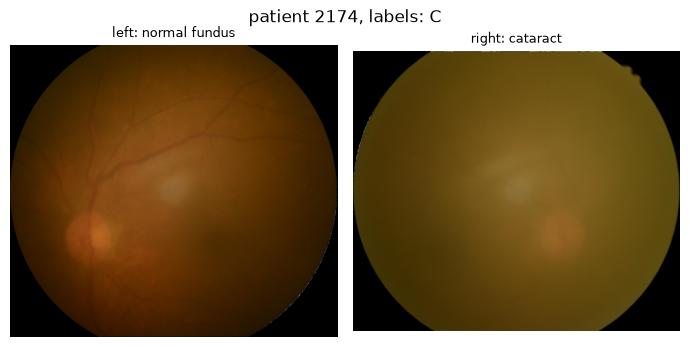

In [4]:
show_patient(eyes, 2174);

`crop_to_fundus` обрезает фон вокруг круга и делает его чёрным. У 15 снимков одной камеры фон белый, и почти все они с катарактой, так что модель могла бы угадывать болезнь по цвету углов. Ниже обычный снимок и снимок с белым фоном: оригинал, маска и результат обрезки. Картинку сохраняем в `reports/figures/` через `save_figure`.

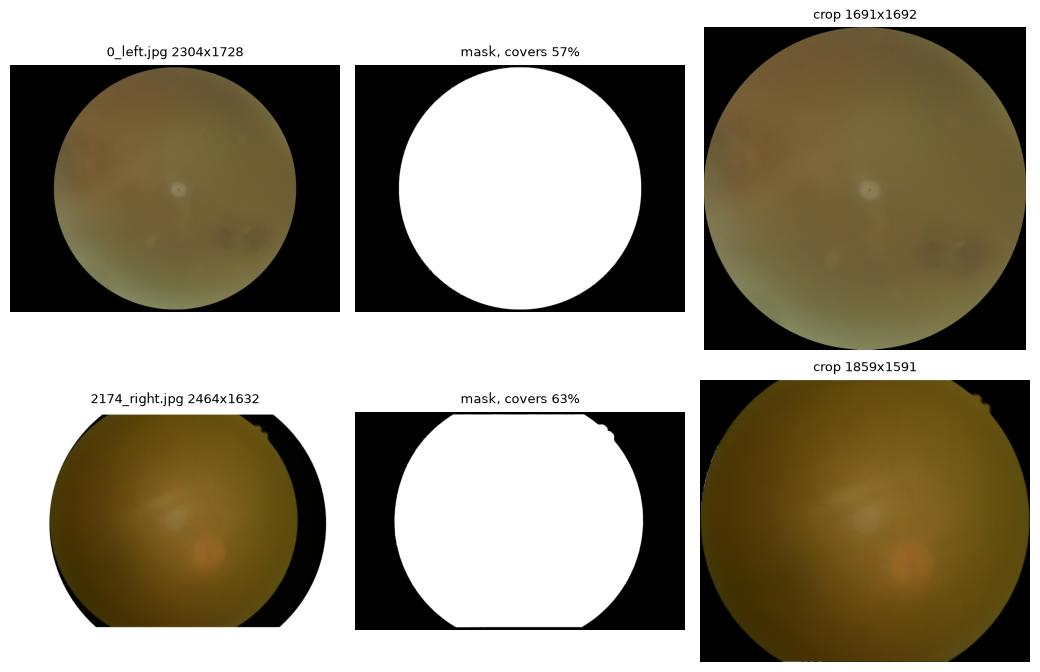

In [5]:
examples = ["0_left.jpg", "2174_right.jpg"]
images, titles = [], []
for name in examples:
    img = load_image(TRAIN_IMAGES_DIR / name)
    mask = fundus_mask(img)
    # Show the boolean mask as a black-and-white RGB image.
    mask_rgb = np.repeat(mask[..., None], 3, axis=2).astype(np.uint8) * 255
    crop = crop_to_fundus(img)
    images += [img, mask_rgb, crop]
    titles += [
        f"{name} {img.shape[1]}x{img.shape[0]}",
        f"mask, covers {mask.mean():.0%}",
        f"crop {crop.shape[1]}x{crop.shape[0]}",
    ]
fig = show_images(images, titles, ncols=3)
save_figure(fig, "intro_crop_examples");

## 5. Пример проверки гипотезы

Свои эксперименты оформляйте так же: гипотеза, зачем, как проверяем, код, результат и вывод. Тогда в конце будет проще собрать общий ноутбук.

**Гипотеза:** метки пациента в `data.xlsx` получены из keywords по простому правилу: если в keyword есть название болезни, ставится эта болезнь; keywords про качество снимка не учитываются; всё остальное идёт в класс O.

**Зачем:** нам нужны метки для каждого глаза отдельно, чтобы обучать модель, которая принимает один снимок.

**Как проверяем:** по этому правилу считаем метки каждого глаза (`eye_labels`), объединяем два глаза в метки пациента (`patient_labels`) и сравниваем с `data.xlsx`.

In [6]:
derived = pd.DataFrame(
    [
        patient_labels(eye_labels(left), eye_labels(right))
        for left, right in zip(
            df["Left-Diagnostic Keywords"], df["Right-Diagnostic Keywords"], strict=True
        )
    ]
)[LABELS]
match = (derived == df[LABELS]).all(axis=1)
print(f"All 8 labels match: {match.sum()} of {len(df)} patients")

All 8 labels match: 3500 of 3500 patients


**Результат:** у всех 3500 пациентов совпали все 8 меток.

**Вывод:** метки в данных поставлены ровно по этому правилу, противоречий между метками и keywords нет. Значит, метки каждого глаза можно брать по этому правилу (колонки `eye_*` в таблице `eyes`).

## 6. Что можно проверить

Идеи для EDA. Пункты 1–9 — про данные, 10–15 — про аугментации.

### 1. Баланс классов

**Что проверяем:** каких болезней много, а каких мало.  
**Зачем:** от этого зависят веса классов при обучении, выбор метрик и разбиение на train / test.  
**Как:** число пациентов и глаз с каждой меткой, столбчатая диаграмма.

### 2. Несколько болезней сразу

**Что проверяем:** сколько болезней бывает у одного пациента и какие встречаются вместе.  
**Зачем:** понять, связаны ли метки между собой.  
**Как:** гистограмма числа меток у пациента и таблица «класс × класс».

### 3. Больной и здоровый глаз

**Что проверяем:** как часто болезнь только на одном глазу.  
**Зачем:** если учить модель на отдельных снимках с метками пациента, здоровый глаз получит метку болезни.  
**Как:** для каждой болезни: у скольких пациентов она на одном глазу, у скольких на обоих (колонки `eye_*`).

### 4. Класс O

**Что проверяем:** что входит в класс O («другое»).  
**Зачем:** там десятки редких болезней, скорее всего это самый трудный класс.  
**Как:** частоты keywords, которые дают O.

### 5. Плохие снимки

**Что проверяем:** правда ли снимки с «low image quality», «lens dust» и похожими keywords плохие, и что с ними делать.  
**Зачем:** по нечитаемому снимку модель не может увидеть болезнь, хотя метка у него есть, и учится на шуме. Но такие снимки будут приходить и в реальной работе, поэтому вариантов три: убрать из обучения, оставить или отсеивать отдельной проверкой качества перед моделью. «lens dust» (пыль на линзе) встречается 408 раз, обычно вместе с нормальным диагнозом, такие снимки, скорее всего, стоит оставить.  
**Как:** посмотреть примеры по каждому такому keyword и проверить, правда ли снимки плохие; сравнить их яркость и резкость с остальными (яркость считать только внутри `fundus_mask`, резкость — после приведения снимков к одному размеру). В выводе написать, какой из трёх вариантов выбираем и почему.

### 6. Ошибки в снимках

**Что проверяем:** все ли снимки — нормальные снимки глазного дна.  
**Зачем:** снимок не того (переднего отдела глаза, пустой кадр, обрезанный, крошечный) — это ошибка в данных, её надо найти до обучения.  
**Как:** найти подозрительные снимки: с keywords «anterior segment image», «no fundus image», самые маленькие (есть шириной 250 px), самые тёмные и самые светлые. Посмотреть на них глазами и записать вывод: какие действительно плохие и что с ними делаем, а какие оказались нормальными.

### 7. Камера подсказывает ответ

**Что проверяем:** связаны ли размер снимка/цвет фона (то есть камера) с болезнью.  
**Зачем:** модель может выучить камеру вместо болезни. Например: на 12 из 15 снимков с белым фоном катаракта.  
**Как:** распределение классов по размерам снимков/цвету фона.

### 8. Возраст и пол

**Что проверяем:** связаны ли болезни с возрастом и полом.  
**Зачем:** возраст и пол известны при диагностике, их можно подавать в модель вместе со снимками. Возраст разметчики учитывали при постановке диагноза.  
**Как:** возраст по классам (boxplot), доли классов у мужчин и женщин.

### 9. Дубликаты

**Что проверяем:** есть ли одинаковые снимки у разных пациентов.  
**Зачем:** копия в train и в test завысит качество модели.  
**Как:** точные копии — по хэшу файла (`hashlib.md5`, стандартная библиотека). Почти-копии (пересжатые, другого размера) — уменьшить снимки до 16×16 в оттенках серого через `cv2.resize` и искать пары с очень маленькой разницей. Новые библиотеки не нужны.

### 10. Аугментации в статьях

**Что проверяем:** какие аугментации и предобработку используют в статьях по ODIR.  
**Зачем:** не изобретать заново.  
**Как:** прочитать несколько статей и выписать аугментации и их параметры в таблицу.

### 11. Отражение

**Что проверяем:** можно ли отражать снимки слева направо.  
**Зачем:** после отражения левый глаз выглядит как правый. Для модели на один глаз это больше данных, для модели на два глаза левый и правый придётся поменять местами.  
**Как:** отражённый левый глаз рядом с настоящими правыми.

### 12. Повороты и масштаб

**Что проверяем:** насколько по-разному повёрнуты и отцентрированы снимки.  
**Зачем:** аугментации должны повторять то, что есть в данных; сильная обрезка может отрезать края, где бывают признаки болезни.  
**Как:** снимки разных классов после поворота на ±15–30° и обрезки до 80–100%.

### 13. Яркость и контраст

**Что проверяем:** насколько отличаются яркость и контраст между снимками.  
**Зачем:** аугментации должны покрывать этот разброс, но не сильно больше.  
**Как:** посчитать среднее и стандартное отклонение по каждому каналу (внутри маски) и разброс яркости и контраста, по нему подобрать диапазон аугментаций. Те же среднее и std нужны для нормализации, но для предобученных моделей обычно берут стандартные значения ImageNet: можно сравнить, насколько они отличаются от наших.

### 14. Цвет

**Что проверяем:** не портит ли изменение цвета признаки болезней.  
**Зачем:** катаракта — мутный желтоватый снимок, при диабете и гипертонии важен цвет сосудов.  
**Как:** снимки с C, D и H до и после изменения цвета.

### 15. Размытие и шум

**Что проверяем:** можно ли имитировать плохие снимки размытием и шумом.  
**Зачем:** размытый здоровый снимок похож на катаракту и может запутать модель.  
**Как:** размытые здоровые снимки рядом со снимками с катарактой.